# CPlink tutorial for SCP data

Here, we provide a simplified and fast demonstration of **CPlink** on GBM SCP data and bulk proteome data that include both tumor and healthy samples. The bulk proteome data were obtained from [Sadiku et al.](https://proteomecentral.proteomexchange.org/ui?pxid=PXD061052), and the SCP data was obtained from [Sadiku et al](https://proteomecentral.proteomexchange.org/ui?pxid=PXD061065).

The processed data in matrix format also can be obtained from [here](https://drive.google.com/drive/folders/1zeWyAYn_l8wbMHnawMBIWPqnu6ne4k0w?usp=sharing)

In [1]:
library(DEP2)
library(Seurat)
library(ggplot2)
library(CPlink)
library(CelliD)
set.seed(2025)

载入需要的程辑包：SummarizedExperiment

载入需要的程辑包：MatrixGenerics

载入需要的程辑包：matrixStats


载入程辑包：‘MatrixGenerics’


The following objects are masked from ‘package:matrixStats’:

    colAlls, colAnyNAs, colAnys, colAvgsPerRowSet, colCollapse,
    colCounts, colCummaxs, colCummins, colCumprods, colCumsums,
    colDiffs, colIQRDiffs, colIQRs, colLogSumExps, colMadDiffs,
    colMads, colMaxs, colMeans2, colMedians, colMins, colOrderStats,
    colProds, colQuantiles, colRanges, colRanks, colSdDiffs, colSds,
    colSums2, colTabulates, colVarDiffs, colVars, colWeightedMads,
    colWeightedMeans, colWeightedMedians, colWeightedSds,
    colWeightedVars, rowAlls, rowAnyNAs, rowAnys, rowAvgsPerColSet,
    rowCollapse, rowCounts, rowCummaxs, rowCummins, rowCumprods,
    rowCumsums, rowDiffs, rowIQRDiffs, rowIQRs, rowLogSumExps,
    rowMadDiffs, rowMads, rowMaxs, rowMeans2, rowMedians, rowMins,
    rowOrderStats, rowProds, rowQuantiles, rowRanges, rowRanks,
    rowSdDiffs, rowSds, rowSums2, rowTabulates, rowV

In [2]:
setwd("~/SCP/")

# Load preprocessed data

In [3]:
bulk_data <- readRDS("bulk_data.rds")
Phenotype <- readRDS("phenotype.rds")
seurat_obj <- readRDS("sc_seurat.rds")

# Identifying phenotype-specific proteins from bulk data and getting cell-cell similarity graph and data matrix from target

In [4]:
#bulk_meta$phenotype <- factor(bulk_meta$phenotype)
#Phenotype <- relevel(Phenotype, ref = "normal")
PS_proteins <- run_DEP2(bulk_data, Phenotype, replicate = c(1:29), p_adj = F)
PS_mtx <- data.frame(markers=PS_proteins[[2]]$ID, logFC=PS_proteins[[2]]$glioblastoma_vs_normal_ratio)
rownames(PS_mtx) <- PS_proteins[[2]]$ID
PSs <- PS_mtx$markers

filter base on missing number is <= 1 in at least one condition.


filter base on missing number fraction < 0.5 in each row


载入需要的名字空间：imputeLCMD

Imputing along margin 2 (samples/columns).



[1] 0.626588


Tested contrasts: glioblastoma_vs_normal

BH



In [5]:
data_matrix <- as.matrix(GetAssayData(seurat_obj, slot = "data"))

nn <- seurat_obj@graphs$SCP_snn

Warning message:
“The `slot` argument of `GetAssayData()` is deprecated as of SeuratObject 5.0.0.
ℹ Please use the `layer` argument instead.”


# Run CPlink

In [7]:
CPlink_out_mtx <- runCPlink(data_matrix, PS_mtx, snn = nn, seed_ratio = NULL, restart_prob = NULL, 
                            sim_methods = "cosine", SigThreshold = 0.05)

Starting CPlink pipeline

Running MCA on phenotype-specific features

Computing Fuzzy Matrix



0.002 sec elapsed


Computing SVD



0.013 sec elapsed


Computing Coordinates



0.001 sec elapsed


Calculating initial phenotype association scores

Restart Probability: 0.05; Seeds Ratio: 0.99

Computing empirical p-values and assign CPlink+ / CPlink- labels

CPlink run completed successfully



# Attach CPlink results to Seurat meta.data

In [8]:
seurat_obj <- seurat_obj
seurat_obj@meta.data <- cbind(seurat_obj@meta.data, 
                                  cbind(CPlink_out_mtx[[1]], CPlink_out_mtx[[2]])[rownames(seurat_obj@meta.data),])

# Visualization

Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.


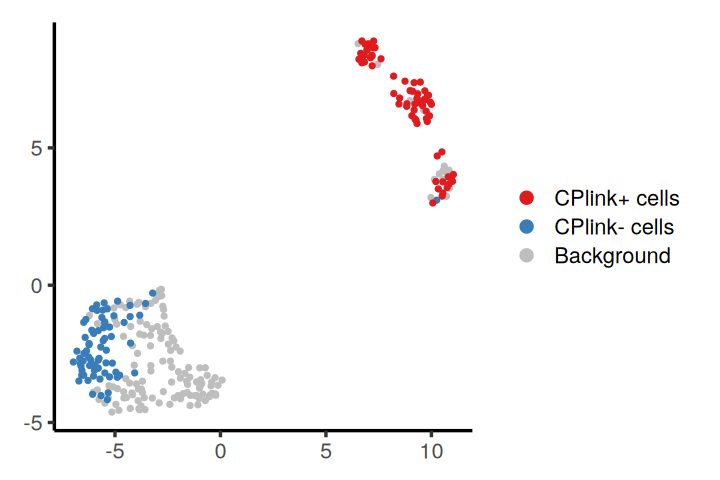

In [9]:
col_p <-c("#e11a1d", "#387db8", "grey" )
seurat_obj@meta.data$cellLabels <- factor(seurat_obj@meta.data$cellLabels, levels=c("CPlink+ cells", "CPlink- cells", "Background"))

options(repr.plot.width=6, repr.plot.height=4)
DimPlot(seurat_obj,reduction="umap",group.by=c("cellLabels"), pt.size = 1,
               label = F, raster=FALSE,
       order=c("CPlink+ cells", "CPlink- cells", "Background"),
        cols = c("#e11a1d", "#387db8", "grey" ))+labs(title = NULL)+
scale_colour_discrete(breaks=c("CPlink+ cells", "CPlink- cells", "Background"), type= c("grey", "#387db8", "#e11a1d"))+
     theme_classic(base_size = 16, base_rect_size = 1.5)+
     theme(#panel.grid = element_blank(), axis.ticks = element_blank(),
         #  legend.position = c(0.8,0.1),
          # panel.border = element_blank(),
          # axis.text = element_blank(),
           axis.title = element_blank(),
           plot.title = element_text( colour = "black"),
          legend.text = element_text( colour = "black")
          )

Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.


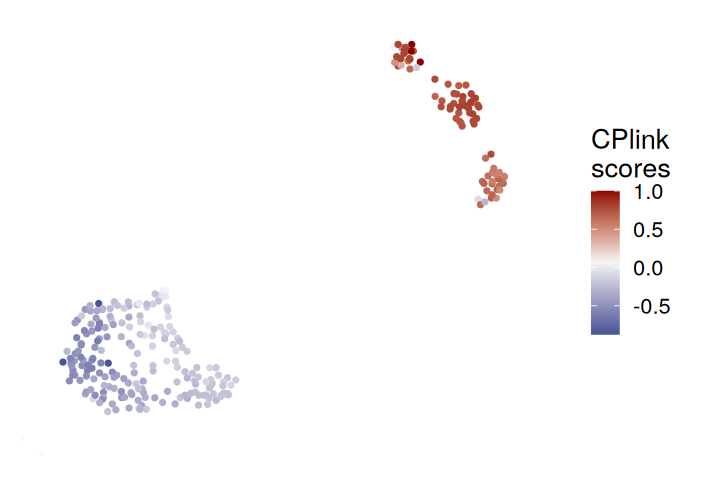

In [10]:
FeaturePlot(seurat_obj,#split.by="disease",
            features = "CPlinkScore", raster=FALSE, label = FALSE) +
            scale_color_gradientn(colors = c("#475496", "#F5F5F5", "darkred"))+#c("lightblue", "white", "darkred")#"#4f5da7", "white", "#ea3433"
labs(title = NULL)+
     theme_bw(base_size = 16, base_rect_size = 1.5)+
#guides(x = axis, y = axis) +
     theme(panel.grid = element_blank(), axis.ticks = element_blank(),legend.position = "right",
           panel.border = element_blank(),
           axis.text = element_blank(),
           axis.title = element_text(size = 0, hjust = 0, colour = "black"), 
           plot.title = element_text( hjust=0.5, colour = "black"),
          legend.text = element_text(colour = "black"),
          #legend.key.width = unit(15, "mm"), #调整图例color bar的宽高
         # legend.key.height = unit(5, "mm"),
         # axis.line = element_line(linewidth = 1, arrow = arrow(type = "closed"))
          ) +
  guides(color = guide_colorbar(title = "CPlink \nscores"))

In [11]:
sessionInfo()

R version 4.3.3 (2024-02-29)
Platform: x86_64-conda-linux-gnu (64-bit)
Running under: Ubuntu 22.10

Matrix products: default
BLAS/LAPACK: /home/server/anaconda3/envs/CPlinkV2/lib/libopenblasp-r0.3.27.so;  LAPACK version 3.12.0

locale:
 [1] LC_CTYPE=zh_CN.UTF-8       LC_NUMERIC=C              
 [3] LC_TIME=zh_CN.UTF-8        LC_COLLATE=zh_CN.UTF-8    
 [5] LC_MONETARY=zh_CN.UTF-8    LC_MESSAGES=zh_CN.UTF-8   
 [7] LC_PAPER=zh_CN.UTF-8       LC_NAME=C                 
 [9] LC_ADDRESS=C               LC_TELEPHONE=C            
[11] LC_MEASUREMENT=zh_CN.UTF-8 LC_IDENTIFICATION=C       

time zone: Asia/Shanghai
tzcode source: system (glibc)

attached base packages:
[1] stats4    stats     graphics  grDevices utils     datasets  methods  
[8] base     

other attached packages:
 [1] CelliD_1.10.1               SingleCellExperiment_1.22.0
 [3] CPlink_0.1.0                ggplot2_3.5.2              
 [5] SeuratObject_5.0.2          Seurat_4.4.0               
 [7] DEP2_0.5.28.2              